# PointMaze (medium maze): BC and IQL

Goal-reaching task: a point mass is controlled to a goal in a maze with a sparse reward. Dataset: Minari `D4RL/pointmaze/medium-v2`. Offline training only; online fine-tuning is omitted because both methods reach full success offline.

## Problem formulation

| | |
|---|---|
| **State** $s \in \mathbb{R}^{8}$ | position $(x, y)$, observation $(x, y, \dot x, \dot y)$ and goal $(g_x, g_y)$ (goal-conditioned) |
| **Action** $a \in [-1, 1]^{2}$ | force in $x$ and $y$ |
| **Reward** | $r = 0$ within 0.45 of the goal, $r = -1$ otherwise (Minari's 0/1 reward shifted by $-1$) |
| **Termination** | goal reached ($d = 1$) |
| **Discount** | $\gamma = 0.99$ |

## Dataset
1,000,000 transitions (4,752 episodes) from a planner and PD controller that drives the ball to a sequence of random goals. Rewards are not relabeled: each transition keeps the goal of its own episode.

## Evaluation protocol
Minari's evaluation maze fixes the goal cell (`g`, bottom right); the start cell is drawn uniformly from the free cells in every episode, and both positions receive uniform noise of ±0.25. Episodes last at most 600 steps. The evaluation maze is checked against the maze in which the data was recorded (`make_eval_env`).

**Metric.** Success rate: the fraction of episodes that reach the goal within the time limit.

## Offline RL setting
Offline reinforcement learning: the policy is learned from a fixed dataset $\mathcal{D} = \{(s, a, r, s', d)\}$ collected by an unknown behavior policy, without interaction with the environment. The environment is used for evaluation only. Value estimates are reliable only for actions represented in $\mathcal{D}$; the methods below avoid querying the critic on out-of-distribution actions.

## Usage
1. Copy the project folder (`offline-rl-jax/`) to Google Drive, e.g. `MyDrive/offline-rl-jax`.
2. Open this notebook in Colab with a GPU runtime (`Runtime → Change runtime type → T4 GPU`).
3. Set `PROJECT_DIR` in Section 1 if the folder is elsewhere, then run all cells.

Outputs are written to the project folder: `results/<name>/` (JSON and figures, tracked by git) and `checkpoints/<name>/` (network weights, not tracked).

## 1. Setup
Mounts Google Drive, sets the working directory and installs the simulator and dataset packages (JAX is preinstalled on Colab).

In [1]:
import os, sys, shutil
PROJECT_DIR = "/content/drive/MyDrive/offline-rl-jax"      # the project folder you uploaded to Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:                                        # running locally instead of Colab
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
if shutil.which("nvidia-smi"):
    os.environ["MUJOCO_GL"] = "egl"                        # headless rendering (only needed for videos)
print("project folder:", PROJECT_DIR)

Mounted at /content/drive
project folder: /content/drive/MyDrive/offline-rl-jax


In [2]:
!pip install -q -r requirements-colab.txt

In [3]:
import numpy as np
import jax
import matplotlib.pyplot as plt
for _m in [m for m in sys.modules if m == "offrl" or m.startswith("offrl.")]:
    del sys.modules[_m]           # always use the code currently in PROJECT_DIR (not a copy cached by an earlier run)
import offrl
from offrl import (Task, Normalizer, to_device, train_offline, EnvPool, evaluate, evaluate_final, summarize,
                   load_config, save_checkpoint, load_checkpoint, save_json, load_json, select_seed)
from offrl.algos.finetune import finetune
from offrl import plotting
print("offrl", offrl.__version__, "from", os.path.dirname(offrl.__file__))
print("JAX", jax.__version__, "| devices:", jax.devices())

offrl 0.3.0 from /content/drive/MyDrive/offline-rl-jax/offrl
JAX 0.11.1 | devices: [CudaDevice(id=0)]


## 2. Settings
Hyperparameters are read from `configs/pointmaze_medium.yaml`.

In [4]:
CONFIG_FILE = "configs/pointmaze_medium.yaml"
cfg, _ = load_config(CONFIG_FILE)
RESULTS_DIR = f"results/{cfg['name']}"            # small files (JSON, figures), meant for GitHub
CKPT_DIR = f"checkpoints/{cfg['name']}"           # trained networks (large, ignored by git)
print(cfg)

{'name': 'pointmaze_medium', 'dataset_id': 'D4RL/pointmaze/medium-v2', 'seeds': [0, 1, 2], 'relabel_to_test_goal': False, 'reward_shift': -1.0, 'goal_radius': 0.45, 'cut_flips': None, 'flip_terminal': False, 'flip_penalty': None, 'batch_size': 256, 'hidden_dim': 256, 'lr': 0.0003, 'actor_lr_schedule': 'cosine', 'bc_steps': 200000, 'iql_steps': 300000, 'eval_every': 50000, 'eval_episodes': 20, 'final_episodes': 50, 'episodes_per_cell': 3, 'discount': 0.99, 'tau': 0.005, 'expectile': 0.7, 'beta': 3.0, 'max_weight': 100.0}


## 3. Data and evaluation environment
`Task` defines the dataset, the evaluation environment, the state representation and the transition labels. States are standardized with the dataset statistics, and the dataset is stored on the GPU. `evaluate_fn` is the evaluation used during training (fixed environment seeds, mean action).

In [5]:
task = Task(cfg)
raw = task.transitions()
normalizer = Normalizer(raw["states"])
DATA = to_device(raw, normalizer)
pool = EnvPool(task)
N_SEEDS = len(cfg["seeds"])
print("state dim:", DATA["s"].shape[1], "| action dim:", DATA["a"].shape[1])

def evaluate_fn(pi):      # the test used during training: deterministic policy mean, eval_episodes per seed
    return evaluate(task, pi, N_SEEDS, cfg["eval_episodes"], 1000, pool, normalizer)

namespace_metadata.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/3.12k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.26k [00:00<?, ?B/s]

... (5 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset D4RL/pointmaze/medium-v2 downloaded to /root/.minari/datasets/D4RL/pointmaze/medium-v2


AdroitHandRelocateDense-v1, AdroitHandHammerDense-v1, AdroitHandDoorDense-v1 environment's reward functions were updated in v1.2.1 without an environment version update. Therefore, use gymnasium-robotics==1.2.0 for v1 reproducibility or use v2 in gymnasium-robotics>=1.4.3. See https://github.com/Farama-Foundation/Gymnasium-Robotics/pull/220 for more details


Eval maze: as given | dataset positions inside walls: 0.00%
    [1, 1, 1, 1, 1, 1, 1, 1]
    [1, 0, 0, 1, 1, 0, 0, 1]
    [1, 0, 0, 1, 0, 0, 0, 1]
    [1, 1, 0, 0, 0, 1, 1, 1]
    [1, 0, 0, 1, 0, 0, 0, 1]
    [1, 0, 1, 0, 0, 1, 0, 1]
    [1, 0, 0, 0, 1, 0, 'g', 1]
    [1, 1, 1, 1, 1, 1, 1, 1]
task: D4RL/pointmaze/medium-v2 (maze) | 4,752 episodes, 1,000,000 steps | test episodes: 600 steps | metric: success
1,000,000 transitions | rewards: own episode goals | goal reached in 4,747 of them (0.47%)
state dim: 8 | action dim: 2


Maze layout with 30 dataset trajectories and the start and goal of one evaluation episode.

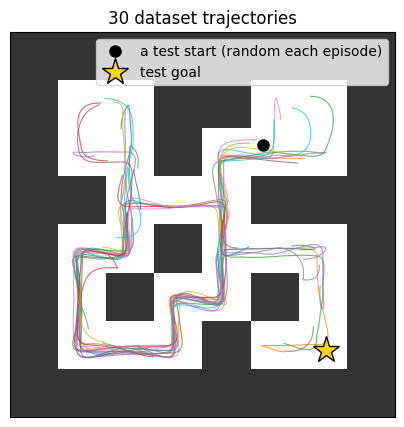

In [6]:
from offrl.envs import draw_maze
obs0, _ = task.env.reset(seed=0)
fig, ax = plt.subplots(figsize=(5, 5))
draw_maze(ax, task.geom)
for e in task.dataset.sample_episodes(min(30, task.dataset.total_episodes)):
    xy = e.observations["achieved_goal"]; ax.plot(xy[:, 0], xy[:, 1], lw=0.8, alpha=0.7)
ax.plot(*obs0["achieved_goal"], "ko", ms=8, label="test start" if task.is_ant else "a test start (random each episode)")
ax.plot(*obs0["desired_goal"], "*", color="gold", ms=20, mec="k", label="test goal")
ax.legend(loc="upper right"); ax.set_title("30 dataset trajectories"); plt.show()

# Part 1: Offline training

## 4. Methods

Both methods train a policy $\pi_\theta(a \mid s)$ on $\mathcal{D}$. All networks are MLPs with two hidden layers of `hidden_dim` units and ReLU activations; the policy mean is passed through $\tanh$ to the action range $[-1, 1]$.

### Behavior cloning (BC)
Regression of the dataset action (`offrl/algos/bc.py`):
$$\mathcal{L}_{BC}(\theta) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\big[\,\lVert \mu_\theta(s) - a \rVert^2\,\big]$$
BC imitates the behavior policy and does not use rewards.

### Implicit Q-Learning (IQL)
Kostrikov, Nair and Levine, *Offline Reinforcement Learning with Implicit Q-Learning*, ICLR 2022 ([arXiv:2110.06169](https://arxiv.org/abs/2110.06169)); `offrl/algos/iql.py`. Three networks are updated on each batch.

**State value** by expectile regression on the target Q-values of dataset actions:
$$\mathcal{L}_V(\psi) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\,L_2^{\tau}\big(\hat Q(s,a) - V_\psi(s)\big)\Big], \qquad L_2^{\tau}(u) = \lvert \tau - \mathbf{1}(u<0)\rvert\, u^2, \qquad \hat Q = \min(Q_{\bar\phi_1}, Q_{\bar\phi_2})$$
For $\tau = 0.5$ this is mean regression; for $\tau > 0.5$ (`expectile`), $V(s)$ approaches the upper range of the Q-values of in-distribution actions, an in-sample estimate of $\max_a Q(s,a)$.

**Action value** by temporal-difference learning with $V(s')$ in place of $\max_{a'} Q(s',a')$:
$$\mathcal{L}_Q(\phi_i) = \mathbb{E}_{(s,a,r,s',d)\sim\mathcal{D}}\Big[\big(r + \gamma\,(1-d)\,V_\psi(s') - Q_{\phi_i}(s,a)\big)^2\Big], \quad i = 1, 2$$
Two critics are used; their target networks are updated as $\bar\phi \leftarrow (1-\tau_t)\bar\phi + \tau_t\phi$ with $\tau_t$ = `tau`. Terminal flags $d = 1$ mark true terminations only, not time limits.

**Policy** by advantage-weighted regression:
$$\mathcal{L}_\pi(\theta) = -\,\mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\min\big(e^{\beta\,(\hat Q(s,a) - V_\psi(s))},\ 100\big)\,\log \pi_\theta(a \mid s)\Big]$$
Dataset actions are weighted by their exponentiated advantage $A = \hat Q - V$; $\beta$ (`beta`) controls the selectivity ($\beta \to 0$ recovers BC). The policy is Gaussian, $\mathcal{N}(\mu_\theta(s), \sigma^2)$, with a learned state-independent $\sigma$; evaluation uses the mean action $\mu_\theta(s)$. The policy learning rate follows a cosine decay over `iql_steps`.

Hyperparameters (config file): `expectile` ($\tau$), `beta` ($\beta$), `discount` ($\gamma$), `tau` (target update rate), `lr`, `batch_size`, `hidden_dim`.

### Training
Seeds are trained in parallel (`jax.vmap`); each block of `eval_every` updates is compiled as one program (`jax.lax.scan`). `train` in the log is training time excluding evaluation; the first block includes compilation. For IQL the log reports the TD loss `q_loss` and the batch mean of $V(s)$.

### 4a. Behavior cloning

In [7]:
bc_states, bc_log = train_offline("bc", cfg, DATA, evaluate_fn)

[BC ] step    50,000 | loss 0.2419 | success [1.00 1.00 1.00] (mean 1.00) | train 13s, total 44s
[BC ] step   100,000 | loss 0.2008 | success [1.00 1.00 1.00] (mean 1.00) | train 25s, total 57s
[BC ] step   150,000 | loss 0.1907 | success [0.95 1.00 1.00] (mean 0.98) | train 36s, total 70s
[BC ] step   200,000 | loss 0.1851 | success [1.00 1.00 1.00] (mean 1.00) | train 47s, total 84s


### 4b. Implicit Q-Learning

In [8]:
iql_states, iql_log = train_offline("iql", cfg, DATA, evaluate_fn)

[IQL] step    50,000 | q_loss 19.412 | V   -54.24 | success [0.90 1.00 0.15] (mean 0.68) | train 56s, total 58s
[IQL] step   100,000 | q_loss 34.780 | V   -77.25 | success [0.95 0.95 0.70] (mean 0.87) | train 109s, total 113s
[IQL] step   150,000 | q_loss 35.971 | V   -78.92 | success [1.00 1.00 1.00] (mean 1.00) | train 161s, total 168s
[IQL] step   200,000 | q_loss 35.633 | V   -79.16 | success [1.00 1.00 1.00] (mean 1.00) | train 215s, total 223s
[IQL] step   250,000 | q_loss 35.188 | V   -79.20 | success [1.00 1.00 1.00] (mean 1.00) | train 268s, total 279s
[IQL] step   300,000 | q_loss 34.603 | V   -79.13 | success [1.00 1.00 1.00] (mean 1.00) | train 322s, total 334s


## 5. Offline results
Final evaluation: `final_episodes` episodes per seed with the mean action, and a success map from every free start cell (`episodes_per_cell` episodes each). Saved to `results/<name>/`.
- **Training curves and final test.** Mean over seeds with a ±1 std band; bars show mean ± std over seeds.
- **Episode outcomes.** Outcome of every final-test episode and the number of steps to reach the goal.
- **Success maps.** Success rate by start cell, averaged over seeds.
- **Value function.** $V(s)$ of IQL (seed 0) over the maze for the test goal.
- **Rollouts.** 20 test episodes of seed 0 (green: goal reached; red: failed, ending in × if flipped, ■ at the time limit) and the distance to the goal over time.

D4RL/pointmaze/medium-v2  (3 seeds, 50 test episodes per seed)
method                          success      all start cells
BC                        1.00 ± 0.00          1.00 ± 0.00  
IQL                       1.00 ± 0.00          1.00 ± 0.00  
saved results/pointmaze_medium/offline_results.json


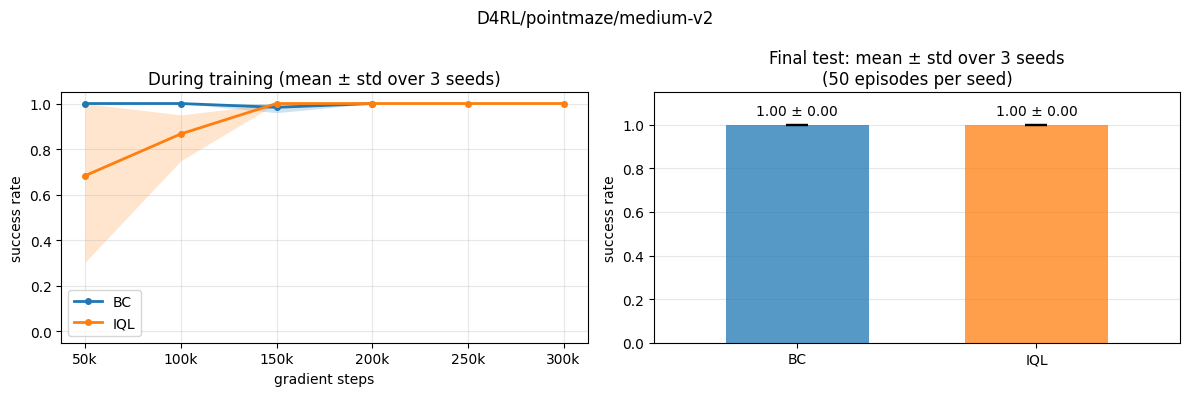

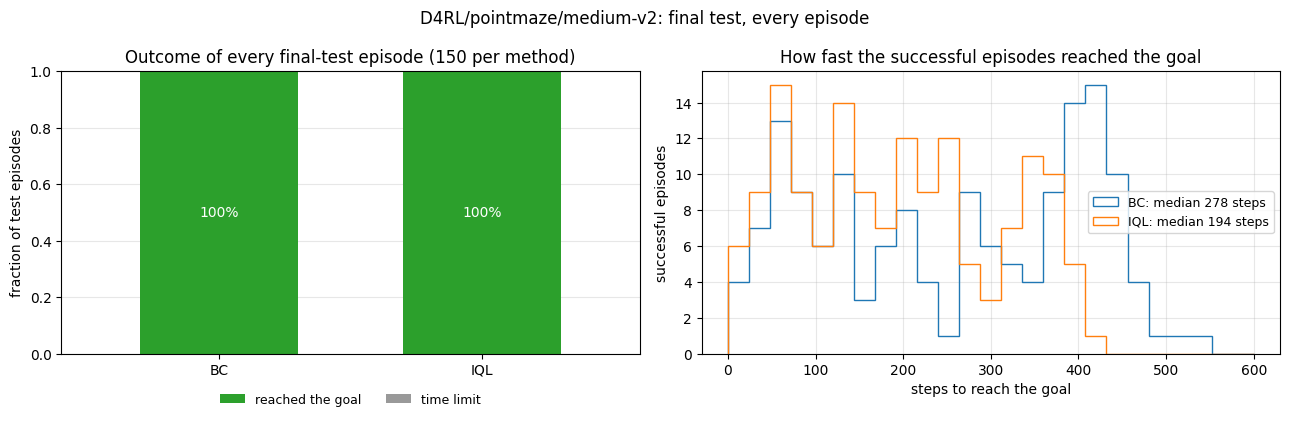

In [9]:
offline_res = evaluate_final(task, cfg, {"BC": bc_states, "IQL": iql_states}, {"BC": bc_log, "IQL": iql_log},
                             pool, normalizer)
summarize(offline_res)
save_json(f"{RESULTS_DIR}/offline_results.json", offline_res)
plotting.plot_offline_results(offline_res, save_path=f"{RESULTS_DIR}/figures/offline.png")
plotting.plot_episode_outcomes(offline_res, save_path=f"{RESULTS_DIR}/figures/offline_episodes.png")

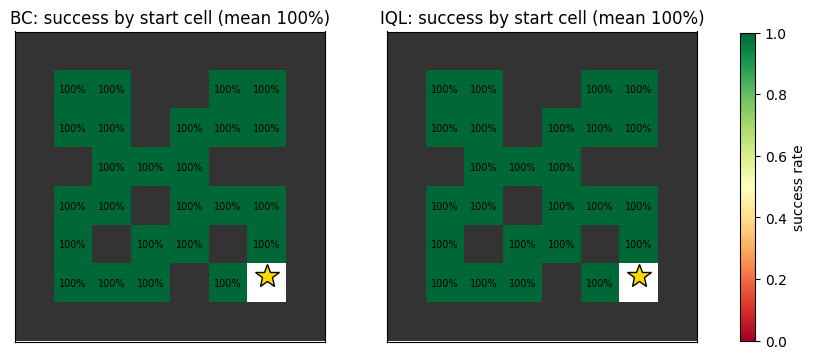

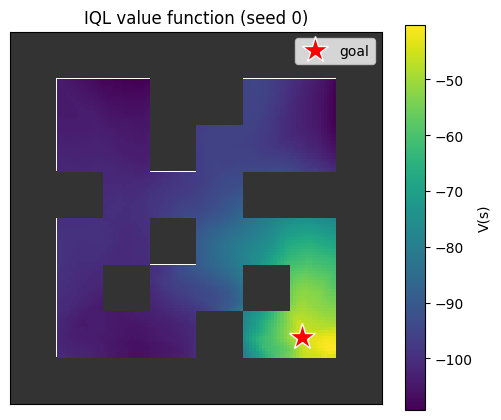

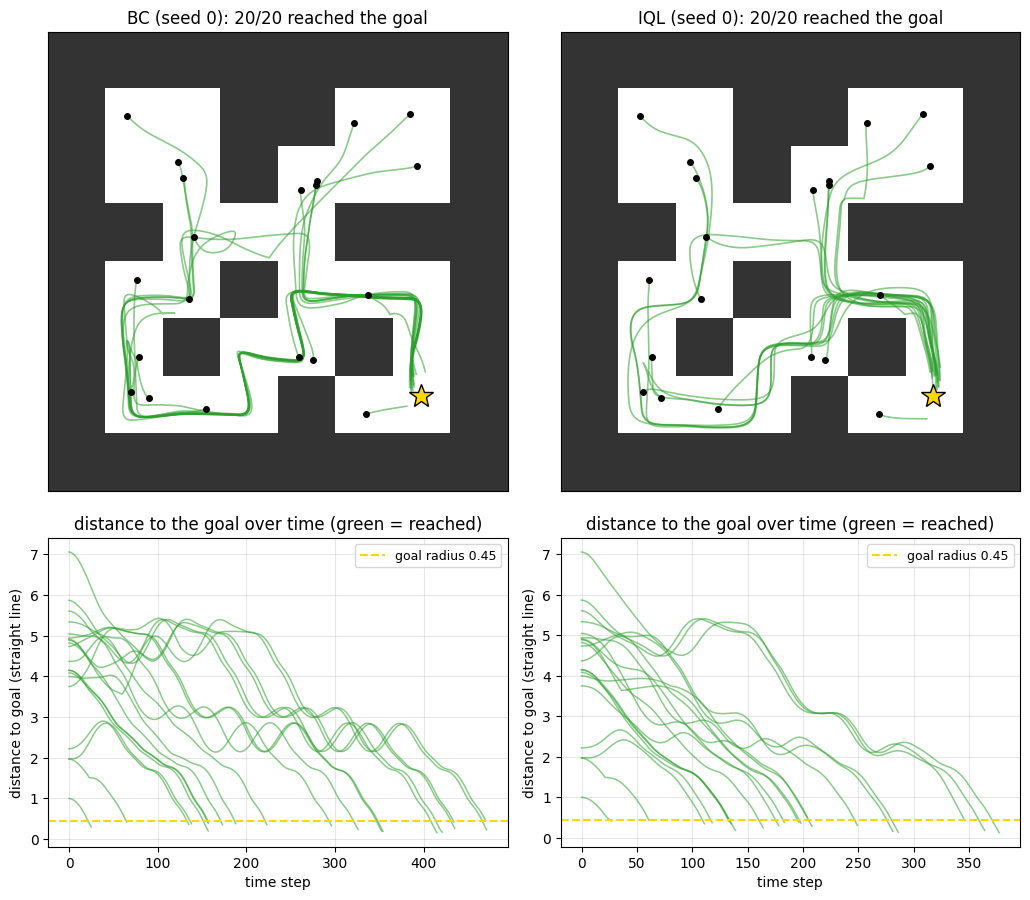

In [10]:
plotting.plot_success_maps(plotting.maps_from_results(offline_res), task.geom, offline_res["goal"],
                           save_path=f"{RESULTS_DIR}/figures/offline_success_maps.png")
plotting.plot_value_heatmap(task, select_seed(iql_states["v"], 0), normalizer,
                            save_path=f"{RESULTS_DIR}/figures/iql_value.png")
plotting.plot_rollouts(task, {"BC": bc_states, "IQL": iql_states}, pool, normalizer, n=20,
                       save_path=f"{RESULTS_DIR}/figures/offline_rollouts.png")

## 6. Checkpoint
Saves the configuration, the state normalizer and the BC and IQL networks (including optimizer states) to `checkpoints/<name>/offline.pkl`.

In [11]:
save_checkpoint(f"{CKPT_DIR}/offline.pkl", config=cfg, normalizer=normalizer.state_dict(),
                bc_states=bc_states, iql_states=iql_states)

saved checkpoints/pointmaze_medium/offline.pkl (14.0 MB)


## 7. Episode recording (optional)
Records one evaluation episode as a GIF (requires rendering). Top-down camera. `seed_index` selects the trained seed.

success at step 346 | return 1.0 -> results/pointmaze_medium/figures/iql.gif


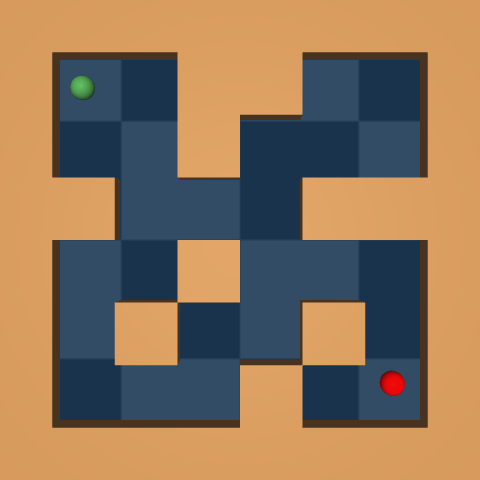

In [13]:
from offrl.video import record_gif
from IPython.display import Image, display
gif_path, _ = record_gif(task, iql_states, normalizer, f"{RESULTS_DIR}/figures/iql.gif", seed_index=0)
display(Image(filename=gif_path))